# Group Members: Jonah Blackmon, Emily Lucas, Kevin Le
# Eids: jkb3578, egl827, kl37995

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np
import re

%matplotlib inline

pd.__version__

 

'3.0.3'

# Load and Merge

In [5]:
outcome_df = pd.read_csv(filepath_or_buffer="./adoption_data_outcome.csv").drop_duplicates()
intake_df = pd.read_csv(filepath_or_buffer="./adoption_data_intake.csv").drop_duplicates()

intake_df["DateTime"] = pd.to_datetime(intake_df["DateTime"], format="%m/%d/%Y %I:%M:%S %p")
outcome_df["DateTime"] = pd.to_datetime(outcome_df["DateTime"].str[:19])  # some rows carry a timezone suffix

# pair same animal visits
intake_df = intake_df.sort_values(["Animal ID", "DateTime"])
outcome_df = outcome_df.sort_values(["Animal ID", "DateTime"])
intake_df["Visit"] = intake_df.groupby("Animal ID").cumcount()
outcome_df["Visit"] = outcome_df.groupby("Animal ID").cumcount()

df = pd.merge(intake_df, outcome_df[["Animal ID", "Visit", "DateTime", "Outcome Type"]],
              on=["Animal ID", "Visit"], how="inner", suffixes=("", " Outcome"))

# drop pairs where the outcome is before the intake (stay started before the dataset did)
stay_days = (df["DateTime Outcome"] - df["DateTime"]).dt.total_seconds() / 86400
df = df[stay_days >= -1].copy()

print(df.shape)
display(df.head())


(172673, 15)


,Animal ID,Name,DateTime,MonthYear,Found Location,Intake Type,Intake Condition,Animal Type,Sex upon Intake,Age upon Intake,Breed,Color,Visit,DateTime Outcome,Outcome Type
0,A006100,Scamp,2014-03-07 14:26:00,March 2014,8700 Research in Austin (TX),Public Assist,Normal,Dog,Neutered Male,6 years,Spinone Italiano Mix,Yellow/White,0,2014-03-08 17:10:00,Return to Owner
1,A006100,Scamp,2014-12-19 10:21:00,December 2014,8700 Research Blvd in Austin (TX),Public Assist,Normal,Dog,Neutered Male,7 years,Spinone Italiano Mix,Yellow/White,1,2014-12-20 16:35:00,Return to Owner
2,A006100,Scamp,2017-12-07 14:07:00,December 2017,Colony Creek And Hunters Trace in Austin (TX),Stray,Normal,Dog,Neutered Male,10 years,Spinone Italiano Mix,Yellow/White,2,2017-12-07 00:00:00,Return to Owner
3,A047759,Oreo,2014-04-02 15:55:00,April 2014,Austin (TX),Owner Surrender,Normal,Dog,Neutered Male,10 years,Dachshund,Tricolor,0,2014-04-07 15:12:00,Transfer
4,A134067,Bandit,2013-11-16 09:02:00,November 2013,12034 Research Blvd in Austin (TX),Public Assist,Injured,Dog,Neutered Male,16 years,Shetland Sheepdog,Brown/White,0,2013-11-16 11:54:00,Return to Owner


# Exploration before clean

Missing values per column:
Animal ID               0
Name                49706
DateTime                0
MonthYear               0
Found Location          0
Intake Type             0
Intake Condition        0
Animal Type             0
Sex upon Intake         1
Age upon Intake         0
Breed                   0
Color                   0
Visit                   0
DateTime Outcome        0
Outcome Type           46
dtype: int64

Outcome Type:
Outcome Type
Adoption           83883
Transfer           48448
Return to Owner    25605
Euthanasia         10790
Died                1662
Rto-Adopt           1238
Disposal             875
Missing               91
NaN                   46
Relocate              28
Stolen                 5
Lost                   2
Name: count, dtype: int64

Animal Type:
Animal Type
Dog          93942
Cat          68873
Other         8948
Bird           877
Livestock       33
Name: count, dtype: int64

Unique values -> Breed: 3000  Color: 660  Intake Condition: 20

Odd 

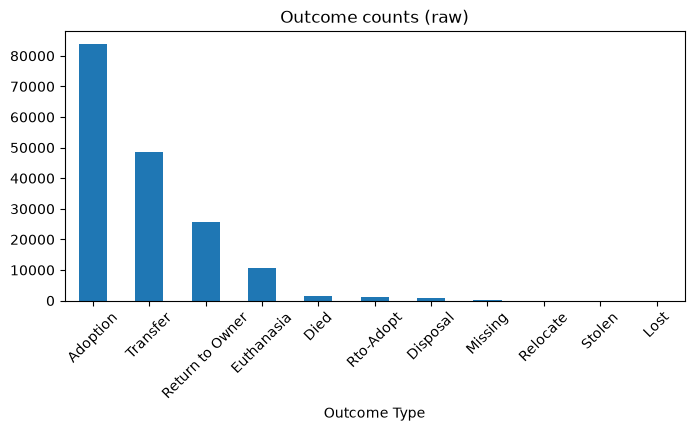

In [6]:
print("Missing values per column:")
print(df.isna().sum())
print("\nOutcome Type:")
print(df["Outcome Type"].value_counts(dropna=False))
print("\nAnimal Type:")
print(df["Animal Type"].value_counts())
print("\nUnique values -> Breed:", df["Breed"].nunique(), " Color:", df["Color"].nunique(),
      " Intake Condition:", df["Intake Condition"].nunique())
print("\nOdd ages:")
print(df[df["Age upon Intake"].str.startswith(("-", "0"))]["Age upon Intake"].value_counts())
print("\nStays per animal:")
print(df.groupby("Animal ID").size().clip(upper=5).value_counts().sort_index())

df["Outcome Type"].value_counts().plot.bar(title="Outcome counts (raw)", rot=45, figsize=(8, 3.5))
plt.show()

# Cleaning

In [7]:
def age_to_years(age):
    if pd.isna(age):
        return np.nan

    age = age.lower().strip()

    match = re.match(r"(\d+(?:\.\d+)?)\s*(day|days|week|weeks|month|months|year|years)", age)

    if not match:
        return np.nan

    value = float(match.group(1))
    unit = match.group(2)

    conversions = {
        "day": 1 / 365.25,
        "days": 1 / 365.25,
        "week": 7 / 365.25,
        "weeks": 7 / 365.25,
        "month": 1 / 12,
        "months": 1 / 12,
        "year": 1,
        "years": 1
    }

    return value * conversions[unit]

In [8]:
# Four outcome classes
df["Outcome Type"] = df["Outcome Type"].replace({"Rto-Adopt": "Return to Owner"})
df = df[df["Outcome Type"].isin(["Adoption", "Transfer", "Return to Owner", "Euthanasia"])].copy()

df["Age"] = df["Age upon Intake"].apply(age_to_years)
df = df.dropna(subset=["Age", "Sex upon Intake"])

print(df.shape) 
print(df["Outcome Type"].value_counts(normalize=True))


# Unecessary columns
# df = df.drop(columns=["Animal ID", "DateTime", "MonthYear", "Outcome Subtype", "Date of Birth", "Found Location", "Color", "Age upon Outcome"])
# df = df[~((df["Breed"] == "Unknown") &(df["Animal Type"] == "Other"))]
# display(df.head())

(169954, 16)
Outcome Type
Adoption           0.493545
Transfer           0.285054
Return to Owner    0.157913
Euthanasia         0.063488
Name: proportion, dtype: float64


# Exploration after clean

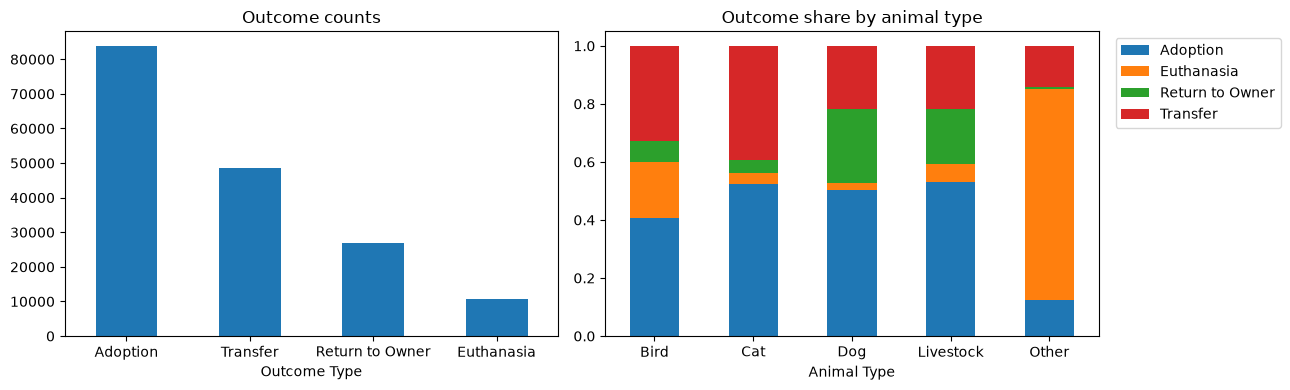

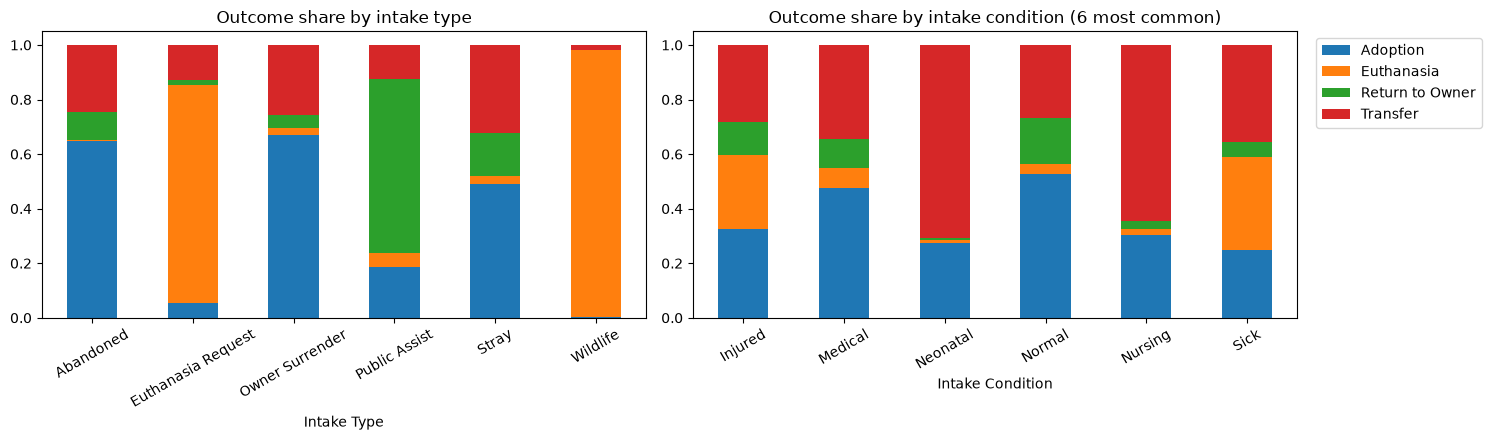

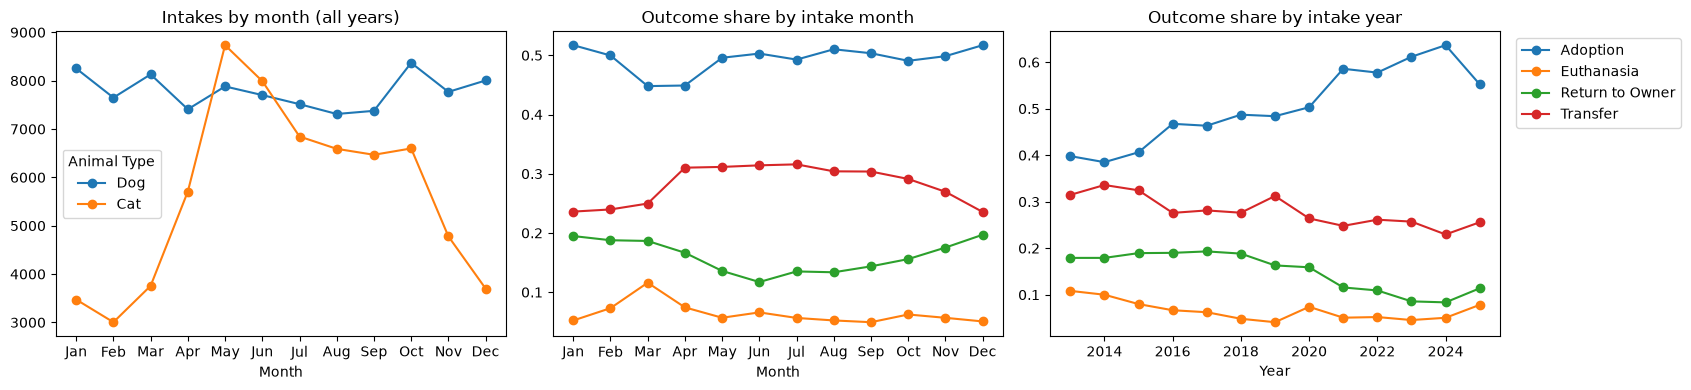

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
df["Outcome Type"].value_counts().plot.bar(ax=ax[0], title="Outcome counts", rot=0)
pd.crosstab(df["Animal Type"], df["Outcome Type"], normalize="index").plot.bar(
    stacked=True, ax=ax[1], title="Outcome share by animal type", rot=0)
ax[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
pd.crosstab(df["Intake Type"], df["Outcome Type"], normalize="index").plot.bar(
    stacked=True, ax=ax[0], title="Outcome share by intake type", rot=30, legend=False)
top_cond = df["Intake Condition"].value_counts().head(6).index
pd.crosstab(df[df["Intake Condition"].isin(top_cond)]["Intake Condition"], df["Outcome Type"],
            normalize="index").plot.bar(stacked=True, ax=ax[1],
            title="Outcome share by intake condition (6 most common)", rot=30)
ax[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()



fig, ax = plt.subplots(1, 3, figsize=(17, 4))
pd.crosstab(df["DateTime"].dt.month, df["Animal Type"])[["Dog", "Cat"]].plot(
    ax=ax[0], marker="o", title="Intakes by month (all years)")
pd.crosstab(df["DateTime"].dt.month, df["Outcome Type"], normalize="index").plot(
    ax=ax[1], marker="o", title="Outcome share by intake month", legend=False)

import calendar

months = list(calendar.month_abbr)[1:]

ax[0].set_xticks(range(1, 13))
ax[0].set_xticklabels(months)

ax[1].set_xticks(range(1, 13))
ax[1].set_xticklabels(months)
pd.crosstab(df["DateTime"].dt.year, df["Outcome Type"], normalize="index").plot(
    ax=ax[2], marker="o", title="Outcome share by intake year")
ax[0].set_xlabel("Month"); ax[1].set_xlabel("Month"); ax[2].set_xlabel("Year")
ax[2].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

# Feature Engineering

In [20]:
# # Convert "Name" to a boolean for existence
# df["Name"] = df["Name"].notna().astype(int)
# display(df.head())

In [21]:
# # Multi-label encode breed, can be more than one
# df["Breed"] = df["Breed"].str.replace(" Mix", "", regex=False)

# # Drop NaN outcomes, can't predict that
# # df = df.dropna()

# breed_encoded = df["Breed"].str.get_dummies(sep="/")
# breed_encoded = breed_encoded.add_prefix("Breed_")
# df = pd.concat([df.drop(columns=["Breed"]), breed_encoded], axis=1)
# display(df.head())

In [22]:
# df["Age upon Intake"] = df["Age upon Intake"].apply(age_to_years)
# display(df.head())

In [23]:
# df["Sex"] = df["Sex upon Intake"].str.extract(r"(Male|Female)", flags=re.IGNORECASE)
# df["Sex"] = df["Sex"].str.capitalize().fillna("Unknown")

# df["Reproductive Status"] = "Unknown"

# df.loc[df["Sex upon Intake"].str.contains(
#     "Neutered", case=False, na=False
# ), "Reproductive Status"] = "Neutered"

# df.loc[df["Sex upon Intake"].str.contains(
#     "Spayed", case=False, na=False
# ), "Reproductive Status"] = "Spayed"

# df.loc[df["Sex upon Intake"].str.contains(
#     "Intact", case=False, na=False
# ), "Reproductive Status"] = "Intact"

# df = df.drop(columns=["Sex upon Intake", "Sex upon Outcome"])
# display(df.head())

In [24]:
# animal_encoded = pd.get_dummies(df["Animal Type"], prefix="Animal", dtype=int)
# df = pd.concat([df.drop(columns=["Animal Type"]), animal_encoded], axis=1)

# categorical_cols = ["Intake Type", "Intake Condition", "Sex", "Reproductive Status"]
# df = pd.get_dummies(df, columns=categorical_cols, dtype=int)

# display(df.head())

In [25]:
# df = df.drop(columns=["Breed_Unknown", "Animal_Other"])
# display(df.head())

In [26]:
# # Move outcome type to the last column
# outcome = df.pop("Outcome Type")
# df["Outcome Type"] = outcome
# df = df.dropna(subset="Outcome Type")
# display(df.head())